# Cyclone sensor data — Task 1

Three and a half years of 5-minute readings from six cyclone tags (2017-01-01 → 2020-08-07). The notebook goes in the order of the brief: cleaning → shutdowns → operating states → anomalies and root causes → 1-hour forecast → insights.

The heavy lifting lives in the small `cyclone/` package next to this notebook. Each module's docstring explains the method choices, and the notebook carries the reasoning tied to what the data showed.

**Run:** from the repo root, `uv sync`, put `data.xlsx` in `given/`, then *Restart & Run All*. It takes about 3 minutes on a laptop; the first run also caches the xlsx as parquet.

In [1]:
import os
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cyclone import anomalies as an, forecasting as fcm, plots, shutdowns as sd, states as st
from cyclone.data import SENSORS, SHORT, clean, load_raw

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

# Raw export: ../given/data.xlsx by default, or set CYCLONE_DATA=/path/to/data.xlsx
DATA = Path(os.environ.get("CYCLONE_DATA", "../given/data.xlsx"))
OUT, SUPPORT, PLOTS, CACHE = Path("."), Path("supporting_outputs"), Path("plots"), Path("cache")
# the four required CSVs go in Task1/ itself, as the brief lists them; extra detail goes in supporting_outputs/
SUPPORT.mkdir(exist_ok=True)
PLOTS.mkdir(exist_ok=True)
if not (CACHE / "raw.parquet").exists() and not DATA.exists():
    raise FileNotFoundError(f"Raw data not found at {DATA.resolve()}. Copy data.xlsx there or set CYCLONE_DATA.")

## 1. Data preparation

The export mixes numbers with PI-historian status strings (`I/O Timeout`, `Not Connect`, `Unit Down`, …) whenever a tag couldn't be read, so every column loads as text. Cleaning is deliberately limited to values that **cannot be real**:

| issue | rule | why |
|---|---|---|
| status strings | → missing | sensor/communication faults, not measurements |
| 1375.0 repeated exactly on two temperature tags | → missing | transmitter range cap |
| material temp of −185 °C, cone draft of +489 Pa | → missing | physically impossible in this process |
| a temperature tag near ambient (< 100 °C) while the other two read > 500 °C | → missing | signal dropout: heat can't vanish at one point of the gas path |
| any tag frozen at one value for ≥ 20 min while hot | → missing | stale or substituted value (e.g. inlet temp at exactly 800.0 for 25 min); real 0.01-resolution readings never sit still |
| 861 missing timestamps (three whole days + scattered) | reindexed to a strict 5-min grid | required by the brief, and lets gaps be seen |
| gaps ≤ 30 min | time interpolation | short enough that interpolation is honest |
| gaps > 30 min | left missing | interpolating across hours would invent process behaviour |

Statistical outliers are **not** clipped. They are what section 4 is looking for.

In [2]:
raw = load_raw(DATA, CACHE)
df, quality = clean(raw)
quality.to_csv(SUPPORT / "data_quality.csv", index=False)
print(f"{len(raw):,} rows in export -> {len(df):,} on the 5-min grid; "
      f"{df[SENSORS].isna().any(axis=1).sum():,} rows still have a missing tag "
      f"({df[SENSORS].isna().any(axis=1).mean():.1%})")
quality.set_index("sensor")

377,719 rows in export -> 378,580 on the 5-min grid; 5,858 rows still have a missing tag (1.5%)


,Comm Fail,Configure,I/O Timeout,Not Connect,Scan Timeout,Unit Down,physically_invalid,dropout_ambient,stale_value,missing_timestamps,interpolated,still_missing
sensor,,,,,,,,,,,,
Cyclone_Inlet_Gas_Temp,2,108,470,723,17,0,0,34,913,861,115,2984
Cyclone_Gas_Outlet_Temp,2,108,470,723,17,1,28,1,904,861,122,2975
Cyclone_Material_Temp,2,108,470,723,17,271,86,1146,3063,861,725,5086
Cyclone_Inlet_Draft,2,108,470,723,17,2,0,0,748,861,109,2822
Cyclone_cone_draft,2,108,470,723,17,0,4,0,1309,861,334,3160
Cyclone_Outlet_Gas_draft,2,108,470,723,17,1,0,0,748,861,103,2827


`Cyclone_Material_Temp` is clearly the weakest instrument. It has nearly all the `Unit Down` codes, ~1,150 near-ambient dropouts while the gas is hot, and 2–4× the stale samples of any other tag. That feeds into the recommendations at the end.

In [3]:
df[SENSORS].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T.round(1)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Cyclone_Inlet_Gas_Temp,375596.0,727.0,328.9,14.4,23.5,30.2,856.3,882.4,901.1,934.1,969.9,1157.6
Cyclone_Gas_Outlet_Temp,375605.0,715.3,325.6,13.8,23.8,30.2,801.5,871.5,899.3,933.0,961.6,1351.4
Cyclone_Material_Temp,373494.0,752.4,349.7,0.0,0.0,20.8,868.3,913.6,943.8,986.0,1018.2,1369.0
Cyclone_Inlet_Draft,375758.0,-141.2,77.7,-396.4,-236.8,-221.1,-193.5,-169.4,-136.1,0.9,13.8,41.6
Cyclone_cone_draft,375420.0,-164.5,90.2,-459.3,-278.2,-258.8,-226.8,-198.6,-143.6,0.3,1.8,41.2
Cyclone_Outlet_Gas_draft,375753.0,-177.7,99.2,-456.7,-296.6,-277.6,-247.2,-215.2,-169.9,4.7,13.4,40.3


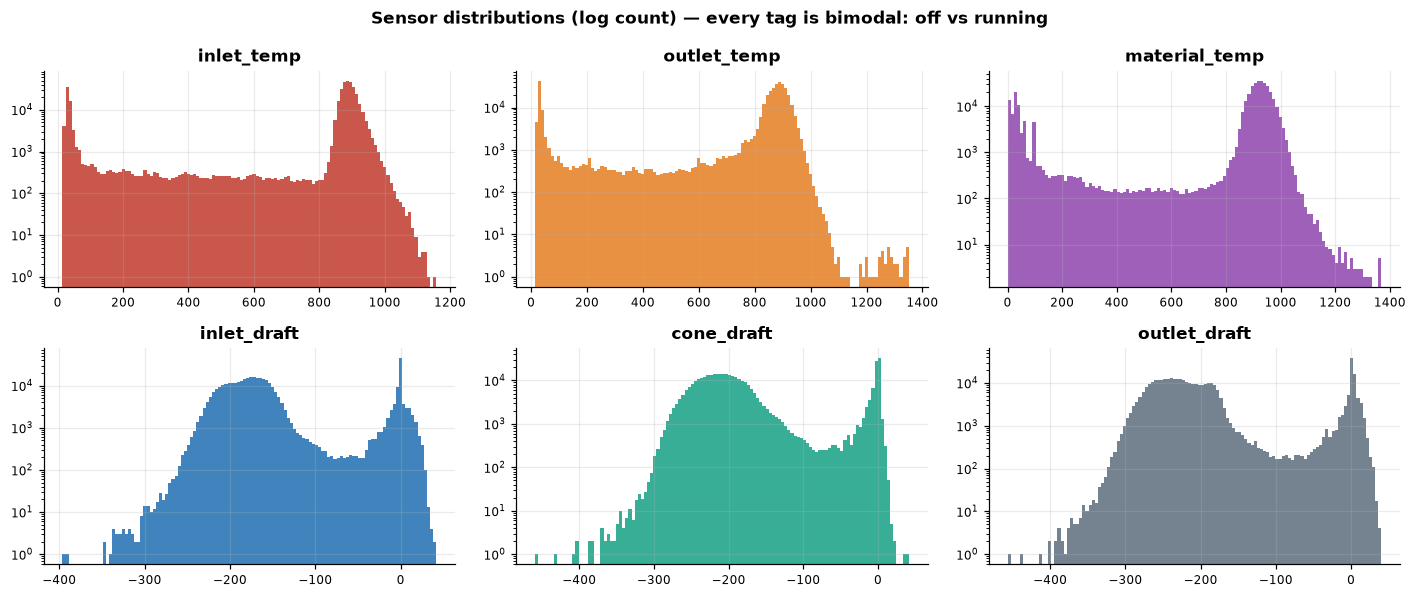

In [4]:
plots.distributions(df, PLOTS / "01_distributions.png");

Every tag is bimodal: one mode for "off" (temperatures near ambient, drafts near 0 Pa) and one for "running". This matters for the correlation matrix. Computed over all rows, it mostly measures the on/off switching, so it is shown for running time as well.

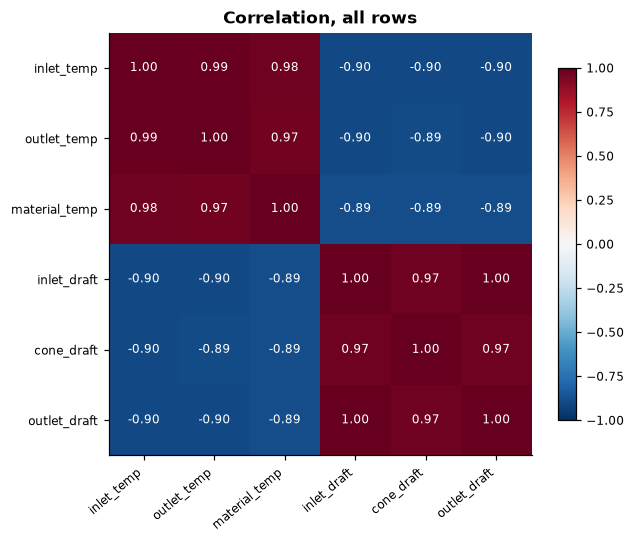

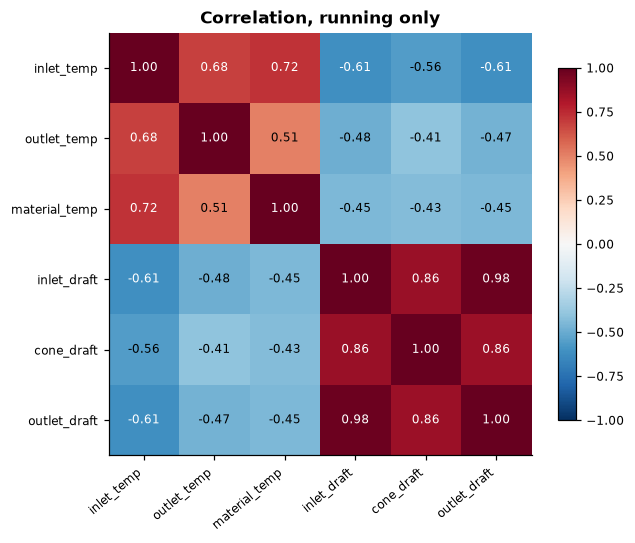

In [5]:
running_rough = df["Cyclone_Inlet_Gas_Temp"] > 500
c_all = df[SENSORS].corr()
c_run = df.loc[running_rough, SENSORS].corr()
plots.correlation(c_all, "Correlation, all rows", PLOTS / "02_corr_all.png")
plots.correlation(c_run, "Correlation, running only", PLOTS / "02_corr_running.png");

Over all rows, inlet vs outlet gas temperature has r = 0.99 and the temperatures vs drafts about −0.9. Restricted to running time, these drop to roughly 0.65 and −0.55. The three drafts remain tightly coupled (0.85–0.98), as expected for one gas path pulled by one fan. In other words, the tags are far less redundant while the plant is running than the headline matrix suggests.

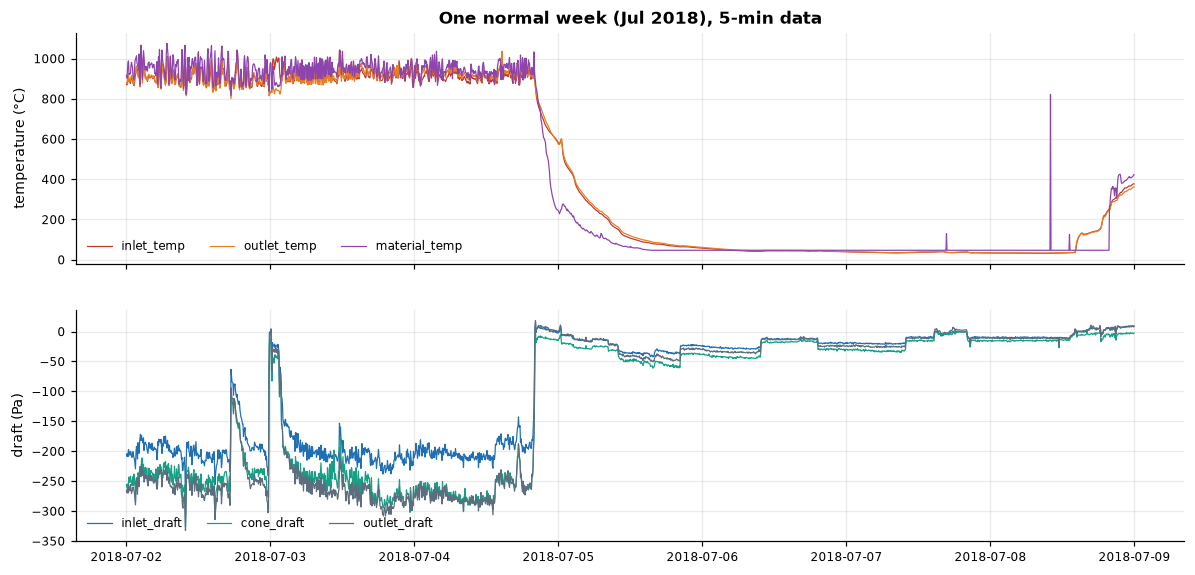

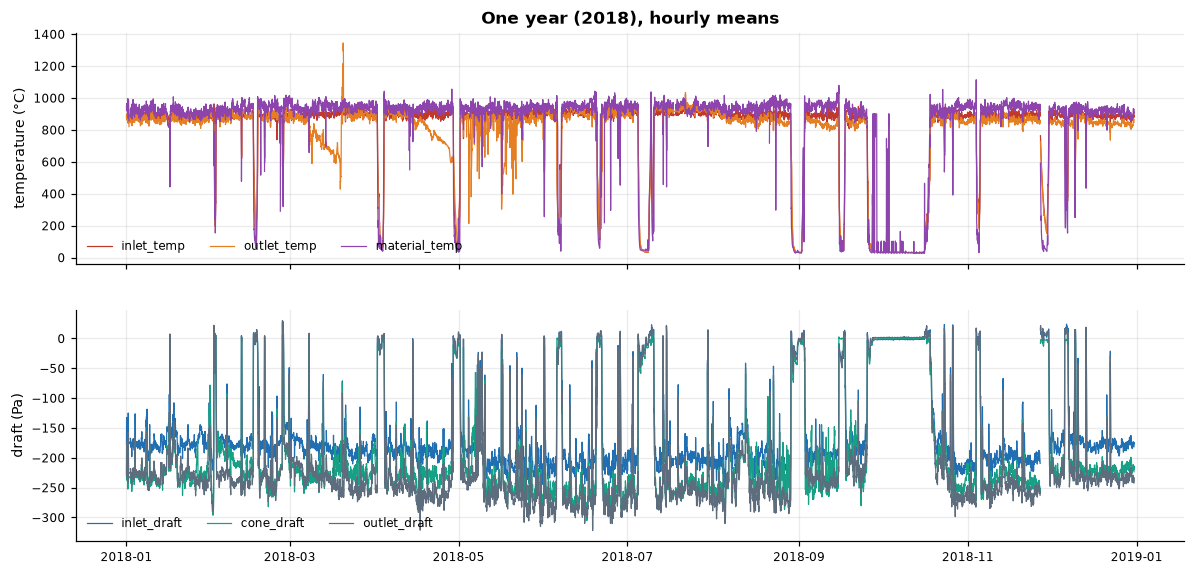

In [6]:
plots.temps_and_drafts(df, "2018-07-02", "2018-07-08 23:55", "One normal week (Jul 2018), 5-min data",
                       path=PLOTS / "03_week.png")
plots.temps_and_drafts(df, "2018-01-01", "2018-12-31 23:55", "One year (2018), hourly means",
                       resample="1h", path=PLOTS / "03_year.png");

In a normal week, inlet gas sits around 850–950 °C with ±30 °C wiggle, and the drafts hold steady between −150 and −250 Pa. Over the year, the obvious structure is the stops. Long ones run for weeks (Sep–Oct), and short dips to zero are trips.

## 2. Shutdown / idle detection

Because inlet gas temperature is so cleanly bimodal, a threshold is the right model here, and anything fancier would only add parameters. The threshold is **not hand-picked**: it is the Otsu split of the histogram (the value that best separates the two modes).

Three rules turn the threshold into events:
- **hysteresis:** off below *T*, back on only above *T* + 100 °C, so a slow ramp crossing *T* doesn't flicker;
- **merge:** stops separated by a restart shorter than 1 h are one stop;
- **minimum length:** events shorter than 30 min are dropped.

Drafts collapsing to ~0 Pa during these periods (fan off) independently confirm the split.

In [7]:
shut, off, T_OFF = sd.detect(df)
print(f"Otsu threshold: {T_OFF:.0f} °C")
print("draft while 'off':", df.loc[off, "Cyclone_Inlet_Draft"].median().round(1),
      "Pa   while running:", df.loc[~off, "Cyclone_Inlet_Draft"].median().round(1), "Pa")
shut.to_csv(OUT / "shutdown_periods.csv", index=False)
sd.summary(shut, df.index)

Otsu threshold: 477 °C
draft while 'off': -1.4 Pa   while running: -178.1 Pa


,year,events,downtime_h,downtime_pct,median_event_h,longest_event_h
0,2017,10,1389.7,15.9,39.6,711.3
1,2018,16,1132.2,12.9,28.7,539.9
2,2019,10,2796.7,31.9,203.2,998.6
3,2020,3,967.1,18.4,21.9,940.5
4,all,39,6285.6,19.9,36.8,998.6


In [8]:
sens = sd.sensitivity(df, T_OFF)
sens

,threshold_c,events,downtime_h
0,327,31,5945.1
1,377,34,6058.8
2,427,37,6186.0
3,477,39,6285.6
4,527,43,6394.7
5,577,47,6476.2


**Robustness:** moving the threshold by ±50 °C changes total downtime by under 2% and the event count by about ±3. The headline numbers don't depend on the exact cut.

,event_id,start,end,duration_h,missing_pct
33,34,2019-09-14 11:15:00,2019-10-26 01:50:00,998.583333,0.0
37,38,2020-03-23 03:40:00,2020-05-01 08:10:00,940.500000,0.0
8,9,2017-09-19 08:45:00,2017-10-19 00:05:00,711.333333,8.9
35,36,2019-11-29 18:40:00,2019-12-24 15:45:00,597.083333,0.0
22,23,2018-09-25 21:05:00,2018-10-18 09:00:00,539.916667,0.0
31,32,2019-06-03 10:20:00,2019-06-22 01:20:00,447.000000,0.0


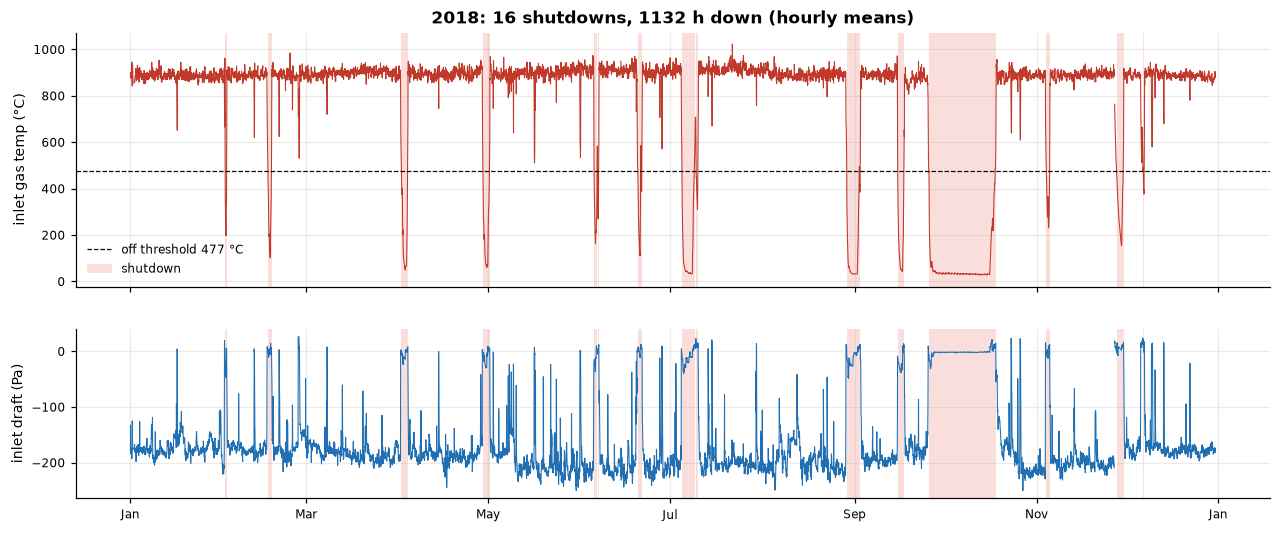

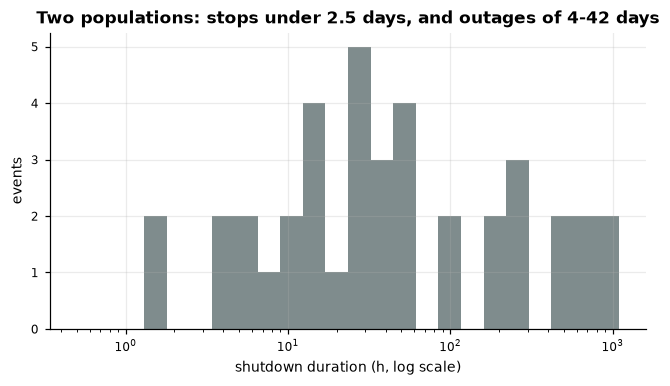

In [9]:
plots.shutdown_year(df, shut, 2018, T_OFF, PLOTS / "04_shutdowns_2018.png")
plots.duration_hist(shut, PLOTS / "04_shutdown_durations.png")
shut.sort_values("duration_h", ascending=False).head(6)

The durations form two separate groups with nothing in between: **26 stops shorter than 2.5 days** and **13 outages of 4–42 days**. The longest stop of each year 2017–2019 starts in the second half of **September** and lasts 3–6 weeks, which is consistent with an annual planned maintenance window. **23 Mar – 1 May 2020** lines up exactly with the national COVID-19 lockdown in India. 2019 is the worst year (32% downtime) because it had several long stops.

## 3. Operating states (running data only)

**Features.** The six raw tags are collinear, so on their own they mostly measure "how hot is the line". Added features capture what an operator would look at:
- `temp_drop` = inlet − outlet gas temperature (heat lost across the cyclone)
- `draft_dp` = inlet − outlet draft (pressure drop across the cyclone, which tracks gas flow and blockage)
- 1-h rolling std of inlet temperature and inlet draft (stability)
- 30-min change of inlet temperature and draft (ramping)

**Model.** Robust scaling → PCA (95% variance, 7 components) → KMeans. Then a 30-minute minimum-dwell filter makes each state an *episode* rather than per-sample flicker.

**Choosing k.**

In [10]:
feats = st.features(df)
active = st.active_mask(df, off, feats)
Fa = feats[active]
print(f"running samples with complete features: {len(Fa):,} ({active.mean():.1%} of the grid)")

pre_k, _, _ = st.fit(Fa, 3)
k_table = st.choose_k(pre_k.transform(Fa))
k_table.round(3)

running samples with complete features: 297,872 (78.7% of the grid)


,k,inertia,silhouette,davies_bouldin
0,3,3708216.703,0.750,0.850
1,4,3234671.373,0.667,0.952
2,5,2885775.483,0.462,0.959
3,6,2574465.765,0.187,1.254
4,7,2401111.717,0.177,1.295


Silhouette points to k = 3, but that is the textbook trap. At k = 3, one cluster holds 96% of running time and the other two are tiny outlying groups, which separate well and so inflate the score. The running data is one continuous cloud, not a set of blobs. HDBSCAN, run below as a cross-check, finds no density clusters at all and calls every sample noise.

So the task is to cut a continuum into **operationally meaningful bands**. k = 6 is the smallest k where each cluster has a distinct physical signature, shown in the table after naming. At k = 7 the extra cluster just splits normal running again.

In [11]:
from sklearn.cluster import HDBSCAN
Xs = pre_k.transform(Fa)
idx = np.random.default_rng(7).choice(len(Xs), 20_000, replace=False)
h = HDBSCAN(min_cluster_size=200).fit(Xs[idx])
print("HDBSCAN on a 20k sample:", h.labels_.max() + 1, "clusters, noise share", f"{(h.labels_ == -1).mean():.0%}")

HDBSCAN on a 20k sample: 0 clusters, noise share 100%


In [12]:
pre, km, raw_labels = st.fit(Fa, 6)
names = st.name_states(Fa, raw_labels)
labels = st.smooth(raw_labels)
print(f"smoothing relabelled {(labels != raw_labels).mean():.1%} of samples; "
      f"{len(st.episodes(raw_labels)):,} raw runs -> {len(st.episodes(labels)):,} episodes")

med = Fa.groupby(labels).median()[SENSORS + ["temp_drop", "draft_dp", "inlet_temp_std_1h", "inlet_draft_std_1h", "inlet_temp_delta_30m"]]
med.index = [names[i] for i in med.index]
med.rename(columns=SHORT).round(1)

smoothing relabelled 12.9% of samples; 57,599 raw runs -> 5,343 episodes


,inlet_temp,outlet_temp,material_temp,inlet_draft,cone_draft,outlet_draft,temp_drop,draft_dp,inlet_temp_std_1h,inlet_draft_std_1h,inlet_temp_delta_30m
High load,901.0,901.7,937.2,-201.2,-230.5,-255.3,-0.7,54.0,16.5,6.0,1.3
Heat-up / warm idle (fan off),617.8,611.7,477.0,10.1,-2.1,10.4,7.4,-1.0,12.2,1.9,-13.4
Trip cool-down (fan off),799.7,794.2,855.2,-1.8,-16.6,-1.8,5.4,4.1,47.4,70.1,-64.2
Unstable draft,896.2,870.4,921.0,-134.9,-161.9,-168.3,25.5,33.2,46.2,25.9,9.1
Normal load,880.9,873.5,915.7,-165.1,-197.6,-206.1,7.3,41.3,13.2,4.4,-1.0
Degraded: high outlet ΔT,895.1,756.2,939.7,-185.6,-221.2,-241.5,142.1,53.1,16.5,5.4,0.2


How the names follow from the medians (the rules are in `states.name_states`):

| state | signature | reading |
|---|---|---|
| **High load** | hottest (~900 °C), strongest draft (~−200 Pa) | full-rate running |
| **Normal load** | ~880 °C, ~−165 Pa | the bulk of running time |
| **Unstable draft** | normal temperatures, but draft std 5× normal | process upsets, oscillating fan or damper control |
| **Degraded: high outlet ΔT** | outlet gas reads ~140 °C below inlet, everything else normal | see the drift plot below: an instrument problem, not a process state |
| **Trip cool-down (fan off)** | draft ≈ 0, temperature falling ~65 °C / 30 min | the ID fan has stopped |
| **Heat-up / warm idle (fan off)** | draft ≈ 0, ~620 °C, material temperature ~480 °C | burner on before the fan starts, or a warm hold |

In [13]:
summary = st.profile(df, Fa, labels, names)
summary.to_csv(OUT / "clusters_summary.csv", index=False)
ep = st.episodes(labels).assign(state=lambda e: e["state"].map(names),
                               duration_h=lambda e: e["steps"] * 5 / 60)
ep[["state", "start", "end", "duration_h"]].to_csv(SUPPORT / "state_episodes.csv", index=False)
summary[["state", "share_of_running_pct", "episodes", "episodes_per_running_month",
         "median_episode_h", "p90_episode_h", "max_episode_h"]]

,state,share_of_running_pct,episodes,episodes_per_running_month,median_episode_h,p90_episode_h,max_episode_h
0,High load,41.4,2159,63.49,1.50,9.18,345.00
1,Heat-up / warm idle (fan off),1.6,121,3.56,2.17,7.00,18.92
2,Trip cool-down (fan off),0.6,189,5.56,0.83,1.00,1.42
3,Unstable draft,2.8,513,15.09,1.17,2.15,4.83
4,Normal load,49.6,2241,65.90,1.75,13.75,127.50
5,Degraded: high outlet ΔT,4.0,120,3.53,2.38,17.41,139.42


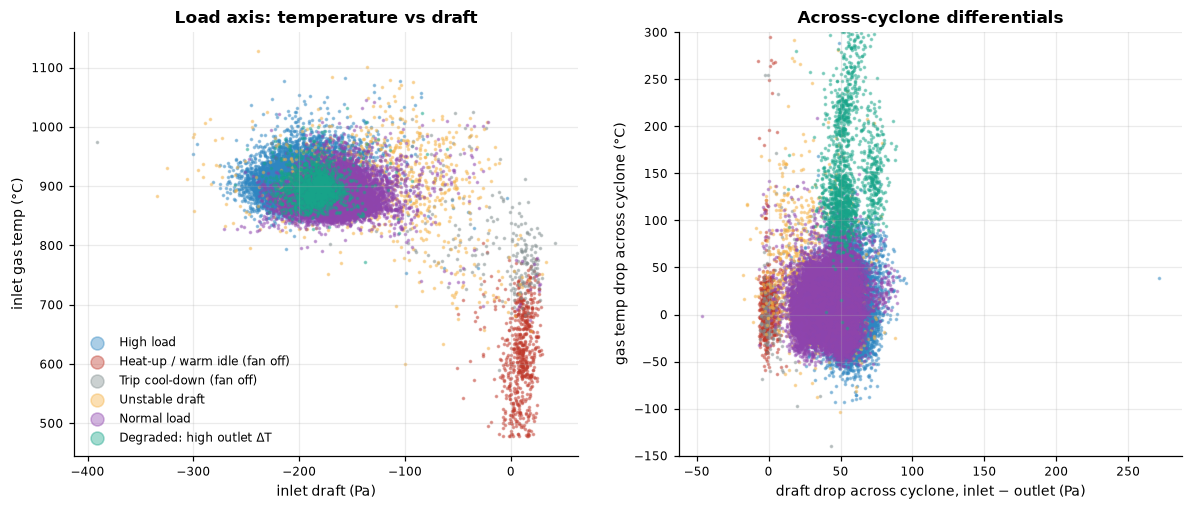

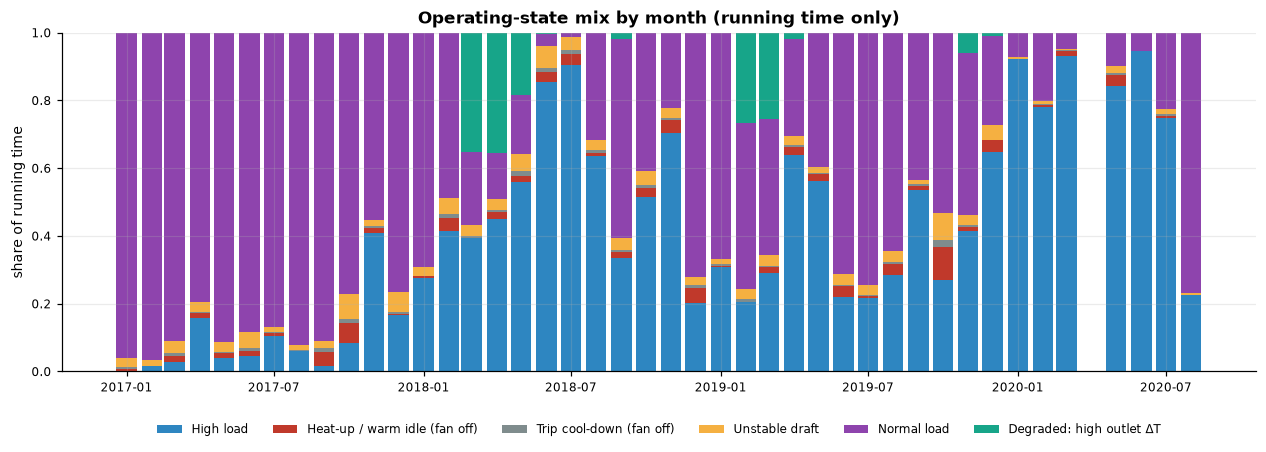

In [14]:
plots.state_scatter(Fa, labels, names, PLOTS / "05_states_scatter.png")
plots.state_share_monthly(labels, names, PLOTS / "05_state_mix_monthly.png");

The monthly mix shows something a single average would hide. The "Degraded" state is concentrated in two blocks, **Mar–May 2018 and Feb–Mar 2019**, and the plant shifts from mostly Normal load in 2017 to mostly High load in 2020.

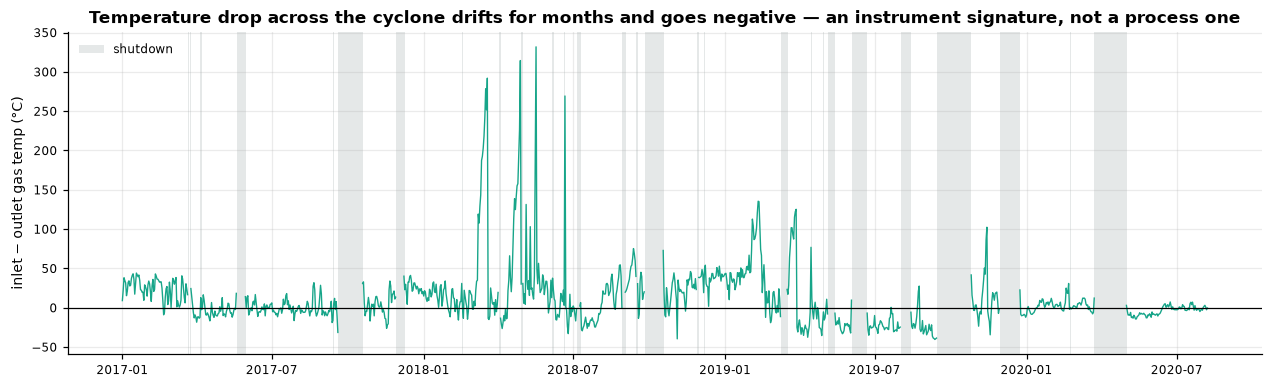

In [15]:
plots.temp_drop_drift(df, active, shut, PLOTS / "06_temp_drop_drift.png");

**This is instrument drift, not a process state.** The daily median of inlet − outlet gas temperature wanders from about +50 °C to about −30 °C over months. It changes in steps around stops (Apr 2019, Oct 2019), and for most of mid-2019 the outlet reads *hotter* than the inlet, which a cyclone with no heat source cannot do. The likely explanation is a thermocouple that drifts and is periodically re-seated or replaced during maintenance. Clustering faithfully isolated these periods as a "state". That is useful, but it also means an anomaly detector conditioned on states will treat them as normal (see section 4).

## 4. Contextual anomaly detection and root causes

**Detector 1: contextual Isolation Forest.** One IF per state, each fitted on that state's own feature distribution, so a reading is judged against what is normal *for that state*. Points above the pooled 99.5th percentile of the score are flagged and grouped into events (15-min gap tolerance; single-sample blips dropped unless extreme). For attribution, robust z-scores (median/MAD within the state) name the tags that moved and their direction.

**Detector 2: upset-state rule.** While building detector 1, a blind spot showed up. The fan trip is so common that it forms its own cluster, "Trip cool-down", so the contextual IF scores a fan trip as *normal for its state*. Every fan-off episode that isn't simply the first step of a detected shutdown is therefore reported:
- `transient_fan_trip`: the next episode has the fan running again (recovered);
- `fan_trip_extended`: the fan stayed off and the line coasted down, then either crossed the shutdown threshold hours later or restarted warm.

In [16]:
scores = an.score(Fa, labels)
anoms = an.build_events(scores, Fa, labels, shut, names)
anoms.to_csv(OUT / "anomalous_periods.csv", index=False)
print(anoms["detector"].value_counts().to_string())
an.rate_by_state(scores, anoms, names)

detector
isolation_forest      180
transient_fan_trip    123
fan_trip_extended      62


,state,running_h,flagged_pct,if_events,if_events_per_1000h
state,,,,,
0,High load,10286.0,0.32,65,6.3
1,Heat-up / warm idle (fan off),406.0,0.51,3,7.4
2,Trip cool-down (fan off),146.0,0.57,0,0.0
3,Unstable draft,689.0,0.21,1,1.5
4,Normal load,12305.0,0.64,100,8.1
5,Degraded: high outlet ΔT,992.0,0.77,11,11.1


duration_min                                           
                          count  mean   std   min   25%   50%   75%    max
detector                                                                  
fan_trip_extended          62.0  53.0   5.0  40.0  50.0  55.0  55.0   75.0
isolation_forest          180.0  36.0  49.0   5.0  15.0  25.0  40.0  445.0
transient_fan_trip        123.0  43.0  12.0  30.0  35.0  40.0  50.0   85.0

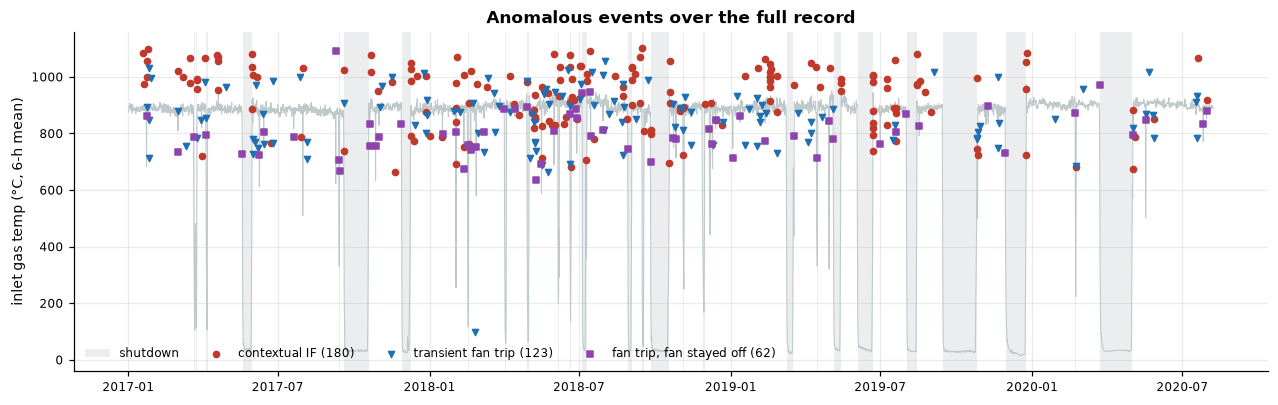

In [17]:
plots.anomaly_timeline(df, anoms, shut, PLOTS / "07_anomaly_timeline.png")
anoms.groupby("detector")[["duration_min"]].describe().round(0)

In [18]:
iso = anoms[anoms["detector"] == "isolation_forest"]
trips = anoms[anoms["detector"] != "isolation_forest"]
print("IF events - primary variable:"); print(iso["primary_variable"].value_counts().to_string())
print("\nfan trips per year:"); print(trips.groupby([trips["start"].dt.year, "detector"]).size().unstack(fill_value=0))

IF events - primary variable:
primary_variable
inlet_draft      63
inlet_temp       53
outlet_draft     33
draft_dp          7
temp_drop         7
material_temp     6
cone_draft        6
outlet_temp       5

fan trips per year:
detector  fan_trip_extended  transient_fan_trip
start                                          
2017                     16                  33
2018                     27                  53
2019                     13                  26
2020                      6                  11


### Root-cause hypotheses for selected events

Five events, each a different kind. Each hypothesis rests on (a) the order in which tags moved, (b) the physical link between them, and (c) the state before and after. These are hypotheses: the data is 5-minute averages, and confirming them needs operator logs, fan current and damper positions.

event_id                                                                         49
start                                                           2017-06-14 11:30:00
end                                                             2017-06-14 12:00:00
duration_min                                                                     30
detector                                                         transient_fan_trip
state                                                      Trip cool-down (fan off)
top_variables               inlet_draft +8.1σ; inlet_temp -6.1σ; outlet_draft +6.0σ
minutes_since_restart                                                        7785.0
minutes_to_next_shutdown                                                    67440.0


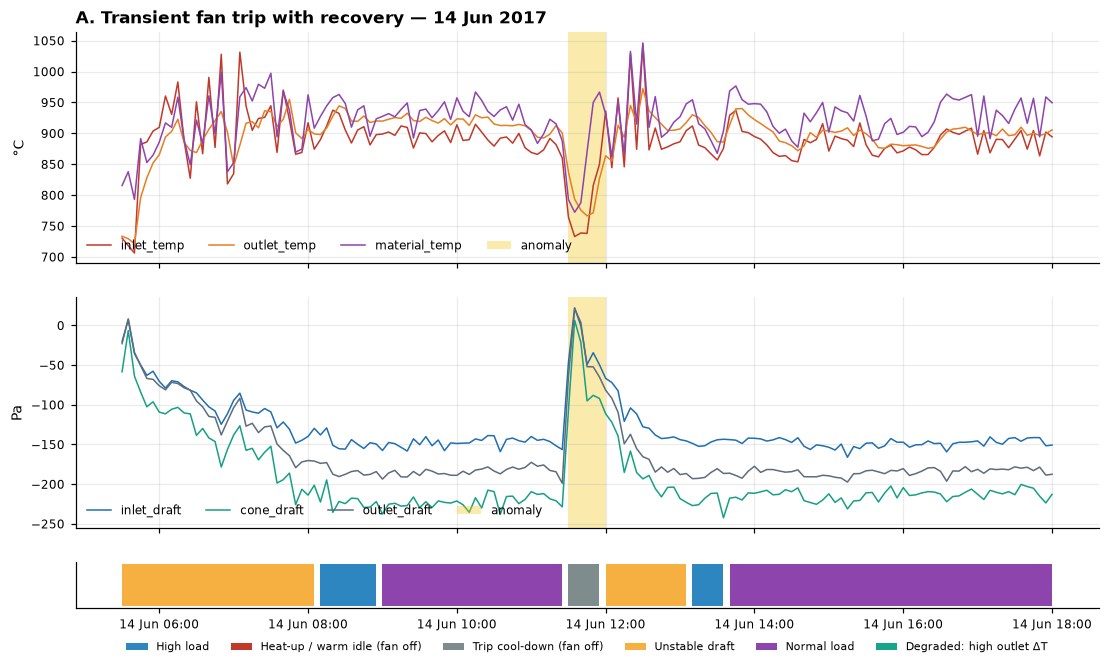

In [19]:
def show(start, title, pad="6h"):
    r = anoms[anoms["start"] == pd.Timestamp(start)].iloc[0]
    print(r[["event_id", "start", "end", "duration_min", "detector", "state", "top_variables",
             "minutes_since_restart", "minutes_to_next_shutdown"]].to_string())
    fname = f"08_rca_{pd.Timestamp(start):%Y%m%d_%H%M}.png"
    plots.anomaly_context(df, labels, names, r, title, pad=pad, path=PLOTS / fname, shutdowns=shut)
    plt.show()

show("2017-06-14 11:30", "A. Transient fan trip with recovery — 14 Jun 2017")

**A. Transient fan trip (14 Jun 2017, 11:30, 30 min).**
*Evidence:* within one 5-min sample, all three drafts go from about −150/−220 Pa to **+20 Pa**. In the same sample, inlet gas falls ~130 °C (860 → 730 °C) and outlet and material temperatures follow. Draft then rebuilds over ~30 min, and temperatures recover to normal within an hour. The state goes Normal load → Trip cool-down → Unstable draft → Normal.
*Hypothesis:* a momentary **ID fan trip** (or damper slam) that the fan control restarted. Losing draft first and temperature second is the signature of reduced gas flow: less hot gas is pulled through, so the temperatures sag. A blockage would instead make the drafts *diverge* (inlet more negative, outlet less), which doesn't happen here.
*This is the most common incident in the record.* About 120 transient trips occurred, roughly one every 8 days of running.

event_id                                                                         88
start                                                           2017-12-27 20:20:00
end                                                             2017-12-27 20:45:00
duration_min                                                                     25
detector                                                           isolation_forest
state                                                                     High load
top_variables               outlet_draft +7.8σ; inlet_draft +6.8σ; cone_draft +4.1σ
minutes_since_restart                                                       27395.0
minutes_to_next_shutdown                                                    51760.0


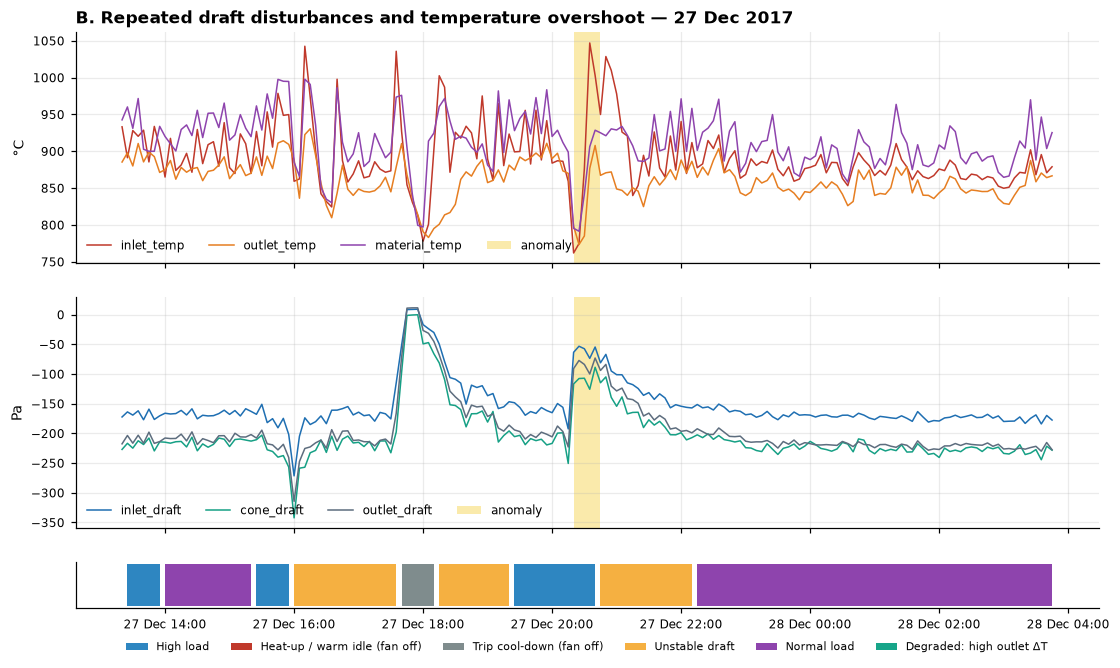

In [20]:
show("2017-12-27 20:20", "B. Repeated draft disturbances and temperature overshoot — 27 Dec 2017", pad="7h")

**B. Chain of draft disturbances (27 Dec 2017).**
*Evidence:* within about six hours there are three draft events. At ~16:00 there is a brief surge *stronger* than normal (−340 Pa). At 17:40 there is a full collapse to 0 Pa (reported separately as a transient trip). At 20:20 a partial loss to about −60 Pa is the flagged event, with high load as context. After each recovery, inlet gas **overshoots** to 1,000–1,050 °C, well above the ~900 °C norm.
*Hypothesis:* an **unstable draft control loop**, such as a sticking damper or a fan speed controller hunting, rather than a single fault. The overshoot after each recovery fits a temperature/fuel controller that kept firing while the gas flow was low, then over-delivered once flow returned. Repeated draft events within hours are worth an operator alert of their own, because the cumulative thermal swings stress refractory and the cyclone shell.

event_id                                                                         59
start                                                           2017-09-09 04:50:00
end                                                             2017-09-09 05:50:00
duration_min                                                                     60
detector                                                          fan_trip_extended
state                                                      Trip cool-down (fan off)
top_variables               inlet_draft +9.3σ; outlet_draft +7.0σ; cone_draft +6.0σ
minutes_since_restart                                                       57040.0
minutes_to_next_shutdown                                                     5805.0


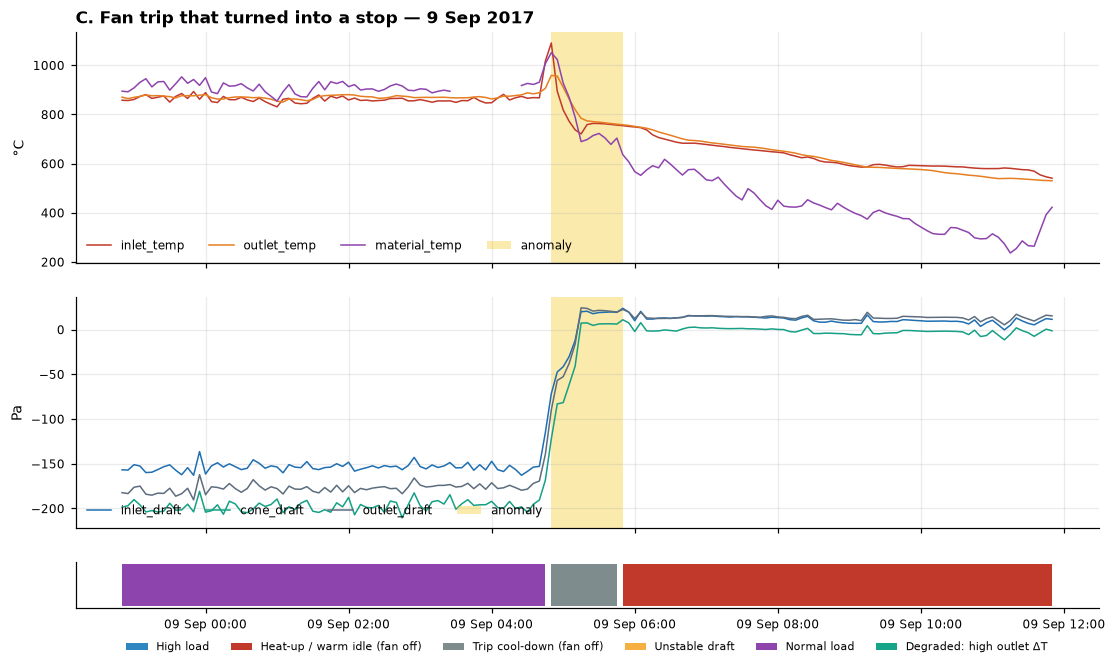

In [21]:
show("2017-09-09 04:50", "C. Fan trip that turned into a stop — 9 Sep 2017", pad="6h")

**C. Fan trip that became a shutdown (9 Sep 2017, 04:50).**
*Evidence:* about an hour earlier, material temperature drops to exactly 0.0 for ~55 min (a dropout, now removed by cleaning). At 04:45 inlet gas **spikes to 1,090 °C** (+9.8σ), and in the same samples the drafts start collapsing. By 05:15 they sit at about +20 Pa and stay there for ~6 h, while the line coasts down to ~580 °C. That is still above the 477 °C threshold, so it never counts as a shutdown. The fan comes back around noon and the line is at normal load by 15:00.
*Hypothesis:* an **ID fan trip that was not restarted for several hours** (a warm hold). The inlet spike is what you would expect when flow stops suddenly: the thermocouple sits in stagnant hot gas near the burner instead of a moving stream. The earlier material temperature dropout may be a coincidence, but a shared electrical or instrument-power fault is worth checking, since two instruments misbehaved within the same hour. The next real shutdown (12 Sep, 21:00) also starts with the draft collapsing before temperatures fall. That turns out to be the typical way stops begin (section 6).

event_id                                                                       174
start                                                          2018-06-21 17:00:00
end                                                            2018-06-21 17:10:00
duration_min                                                                    10
detector                                                          isolation_forest
state                                                Heat-up / warm idle (fan off)
top_variables               temp_drop +14.8σ; cone_draft -9.9σ; outlet_draft -7.3σ
minutes_since_restart                                                         90.0
minutes_to_next_shutdown                                                   19200.0


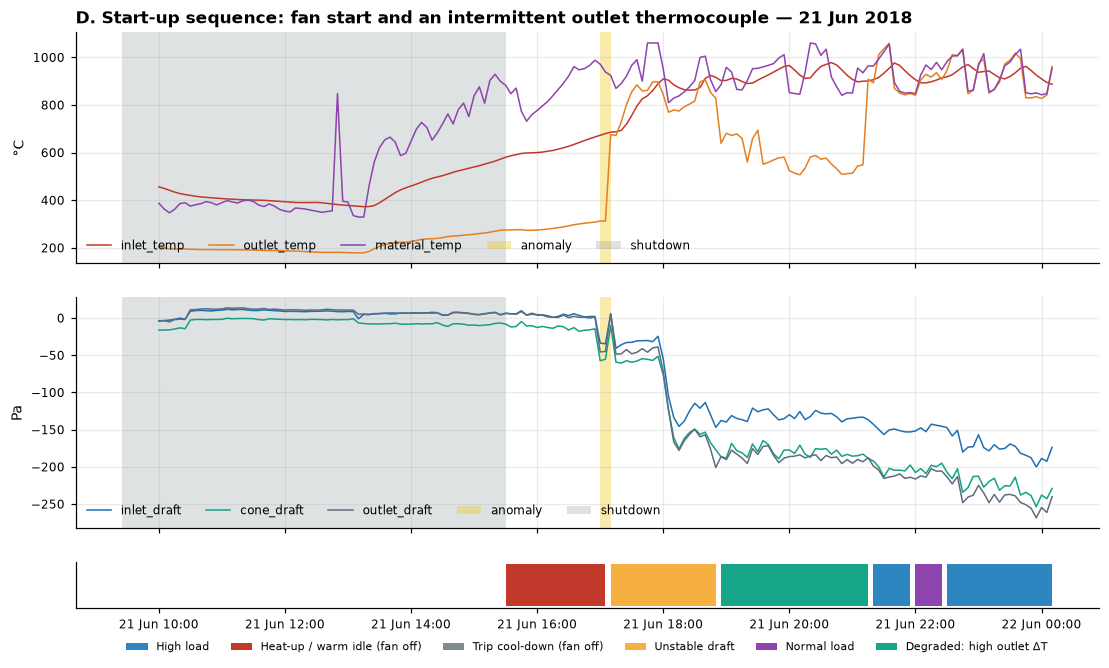

In [22]:
show("2018-06-21 17:00", "D. Start-up sequence: fan start and an intermittent outlet thermocouple — 21 Jun 2018", pad="7h")

**D. Start-up (21 Jun 2018, 17:00), and a false positive worth understanding.**
*Evidence:* this event comes 90 min after a restart. Inlet gas has been climbing with the fan off, while outlet gas lags at ~300 °C. At 17:15 the drafts step to about −50 Pa (fan started) and outlet gas jumps 370 °C in one sample as hot gas reaches it. Later (18:50–21:15), outlet gas drops ~300 °C in a **single step** and comes back in another single step, while inlet, material and drafts stay steady.
*Hypothesis:* the flagged event is **a normal start-up action**, the fan starting, scored as anomalous because start-ups are rare in the training data. The same thing shows up across the whole record: the 2 h after a restart produce IF events at about 20× the base rate (section 6). The later step changes in outlet temperature are an **intermittent thermocouple** (a loose junction or connector). Real gas temperature cannot fall and recover 300 °C instantly while every other tag is flat. This is the same instrument as the drift in section 3.
*Takeaway:* alarms in the first ~2 h after a restart should use a separate, start-up-specific model or wider limits.

time
2019-01-20     51.0
2019-01-27     44.0
2019-02-03     60.0
2019-02-10    104.0
2019-02-17     66.0
2019-02-24     13.0
2019-03-03      5.0
2019-03-10      5.0
2019-03-17     23.0
2019-03-24     78.0
2019-03-31     66.0
2019-04-07    -27.0
2019-04-14    -25.0
2019-04-21     -1.0
Freq: W-SUN


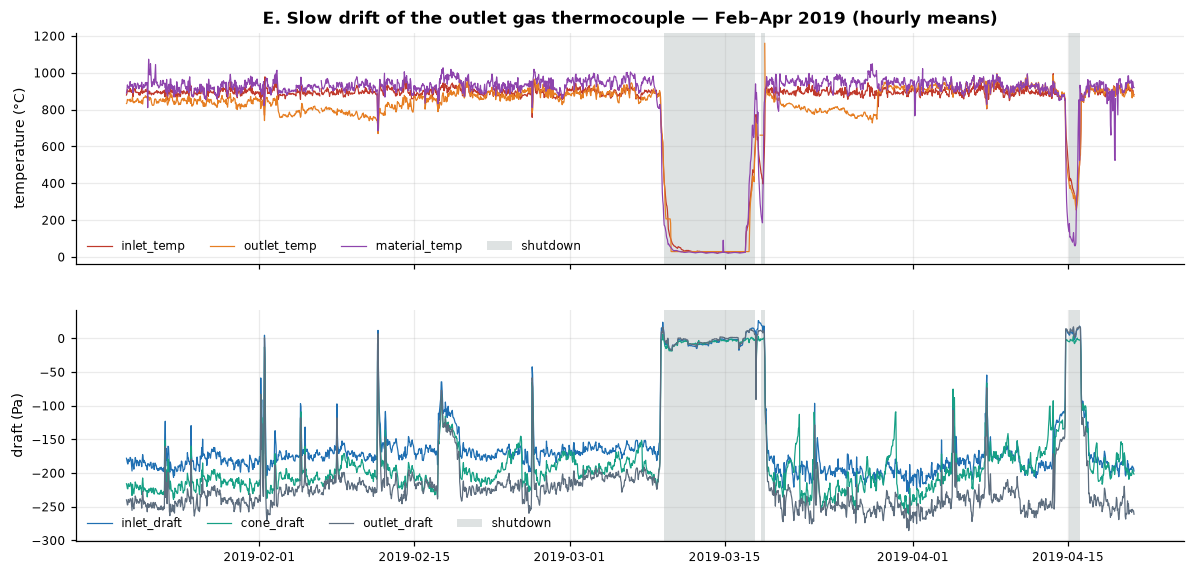

In [23]:
fig = plots.temps_and_drafts(df, "2019-01-20", "2019-04-20 23:55",
    "E. Slow drift of the outlet gas thermocouple — Feb–Apr 2019 (hourly means)",
    shutdowns=shut, resample="1h", path=PLOTS / "08_rca_drift_2019.png")
d = (df["Cyclone_Inlet_Gas_Temp"] - df["Cyclone_Gas_Outlet_Temp"]).where(active)
print(d["2019-01-20":"2019-04-20"].resample("W").median().round(0).to_string())

**E. Slow drift (Feb–Apr 2019): an anomaly no point-detector will catch.**
*Evidence:* twice in this window, outlet gas sags slowly by 100–150 °C while inlet gas holds at ~900 °C: early to mid February, and again 20–28 Mar right after the March stop. Each sag ends in a **single step** back up. Inlet temperature, material temperature and the drafts show nothing matching. After the short stop on 7 Apr 2019 the gap flips to about −25 °C, with the outlet reading *hotter* than the inlet, and stays negative until Sep 2019.
*Hypothesis:* **outlet thermocouple degradation** (drift or fouling of the sheath), with the step changes marking interventions. A real loss of heat across the cyclone would also move material temperature or the pressure drop, and neither moves.
*Why it matters for the design:* a drift lasting weeks becomes the "normal" of its own cluster ("Degraded: high outlet ΔT"), so a contextual detector stops flagging it. Slow drift needs its own monitor: a daily check of inlet − outlet against a long baseline.

## 5. One-hour forecast of inlet gas temperature

- **Split:** train 2017-01 → 2019-12; test 2020-01 → 2020-08. This is chronological, with no shuffling, and the last hour of training targets is dropped so no target crosses into the test period.
- **Origins:** one per hour across the test period, each forecasting t+5 … t+60 min from data up to t.
- **Models:**
  - **persistence** (the baseline);
  - **ARIMA(2,1,2)**, fitted once on the last 4 weeks of training and re-filtered on the trailing 24 h at each origin. This is how it would run online, and it avoids 5,000 refits;
  - **gradient boosting** (sklearn `HistGradientBoostingRegressor`), direct strategy with one model per horizon. Features are lags, rolling stats, the other five tags and their 30-min changes, and time of day.
- **Regimes:** every origin is tagged by what happens within ±1 h. An average over the whole test set mostly reflects how much of it happens to be shut down.

In [24]:
fc, gbm_models = fcm.run(df, T_OFF)
fc.round(2).to_csv(OUT / "forecasts.csv", index=False)
m = fcm.metrics(fc)
m.to_csv(SUPPORT / "forecast_metrics.csv", index=False)
print((fc.groupby("regime")["origin"].nunique()).to_string())
m.pivot(index="subset", columns="model", values=["rmse", "mae"]).round(1)

regime
disturbed          239
shut_down          954
steady_running    4057
transition          12


rmse                     mae                  
model          arima   gbm persistence arima   gbm persistence
subset                                                        
all             16.8  15.1        19.4   9.8   9.5        11.8
disturbed       52.2  41.7        55.4  35.3  27.9        38.7
shut_down        6.2   5.6         5.0   1.3   2.5         0.9
steady_running  13.8  13.6        17.3  10.2  10.0        12.7
transition      37.4  17.2        26.7  31.7  13.1        20.8

,persistence_rmse,persistence_mae,arima_rmse,arima_mae,gbm_rmse,gbm_mae
horizon,,,,,,
1,17.05,12.48,13.24,9.83,12.94,9.55
6,17.23,12.84,13.94,10.40,13.71,10.18
12,17.59,13.08,14.19,10.51,14.10,10.42


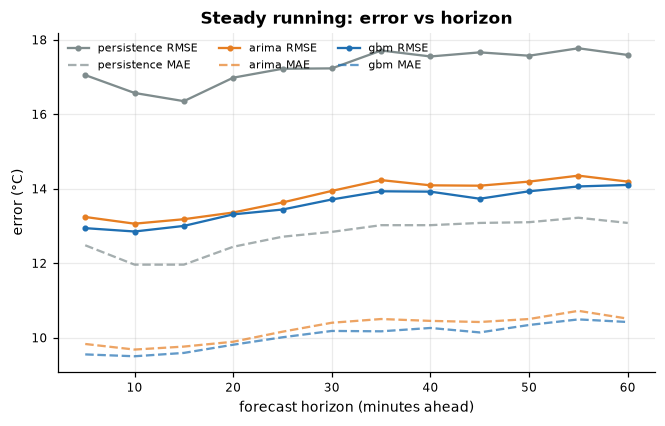

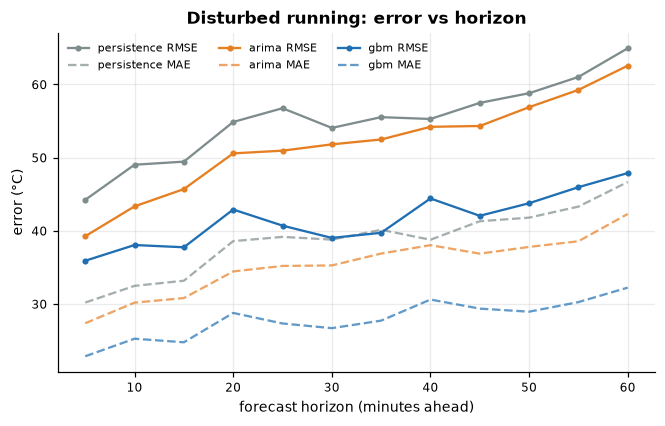

In [25]:
by_h_steady = fcm.metrics_by_horizon(fc, "steady_running")
by_h_dist = fcm.metrics_by_horizon(fc, "disturbed")
plots.forecast_horizon(by_h_steady, "Steady running: error vs horizon", PLOTS / "09_fc_horizon_steady.png")
plots.forecast_horizon(by_h_dist, "Disturbed running: error vs horizon", PLOTS / "09_fc_horizon_disturbed.png")
by_h_steady.iloc[[0, 5, 11]]

In [26]:
# where does the error come from? share of total squared error by regime
se = fc.assign(se_gbm=(fc["pred_gbm"] - fc["y_true"]) ** 2,
               se_persistence=(fc["pred_persistence"] - fc["y_true"]) ** 2)
share = se.groupby("regime")[["se_gbm", "se_persistence"]].sum()
(100 * share / share.sum()).round(1).assign(share_of_origins_pct=(100 * fc.groupby("regime").size() / len(fc)).round(1))

,se_gbm,se_persistence,share_of_origins_pct
regime,,,
disturbed,34.7,37.1,4.5
shut_down,2.5,1.2,18.1
steady_running,62.6,61.3,77.1
transition,0.3,0.4,0.2


In [27]:
# how much of the 5-min movement is noise? white noise around a level gives -0.5
y_run = df["Cyclone_Inlet_Gas_Temp"].where(~off)
dy = y_run.diff()
pd.Series({yr: dy[str(yr)].autocorr(1) for yr in range(2017, 2021)}, name="lag-1 autocorr of 5-min changes").round(2)

2017   -0.47
2018   -0.43
2019   -0.37
2020   -0.47
Name: lag-1 autocorr of 5-min changes, dtype: float64

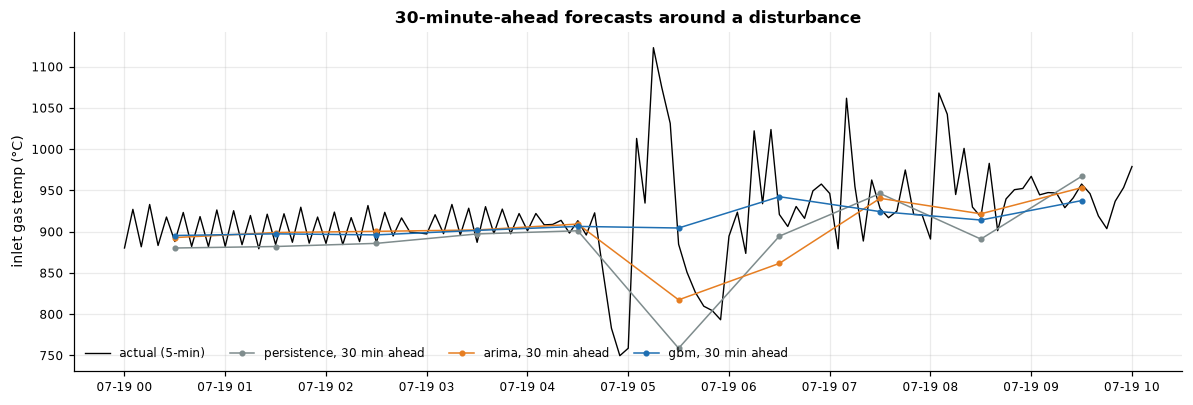

In [28]:
worst = fc[fc["regime"] == "disturbed"].groupby("origin")["y_true"].agg(lambda s: s.max() - s.min()).idxmax()
plots.forecast_example(df, fc, worst - pd.Timedelta("5h"), worst + pd.Timedelta("5h"), horizon=6,
                       path=PLOTS / "09_fc_example.png");

**Reading the results**

- **Steady running (about 77% of origins):** both models beat persistence by about 20% RMSE (≈ 13.6–13.8 vs 17.3 °C). ARIMA and gradient boosting are tied, so linear dynamics are enough when nothing is happening. Error grows only slowly with horizon, and the reason is in the data. Consecutive 5-minute changes have a lag-1 autocorrelation of about −0.43 in every year; pure white noise around a level would give −0.5. So most 5-minute movement is measurement noise around a slowly moving level. Persistence copies that noise into every forecast, while the models predict the level.
- **Disturbed running (4.5% of origins, but about 35% of all squared error):** errors triple for every model. Gradient boosting is clearly best here (≈ 42 vs 52 ARIMA vs 55 persistence RMSE), because the draft features carry the upset before temperature fully reacts. This is the only regime where the non-linear model earns its complexity.
- **Transitions:** there are only 12 origins in the test period, too few to rank models with confidence. ARIMA is worse than persistence here, though, because it extrapolates a trend straight through a regime change.
- **Shut down:** persistence is best, which is trivial, since the temperature is flat near ambient. Gradient boosting's small bias here is the cost of one model covering every regime.

**Practical challenges.** The process is non-stationary: the load mix shifts year to year (section 3), there is the thermocouple drift, and there is the long 2020 lockdown stop. Shutdowns are effectively unforecastable from temperature alone; the first sign is usually the draft. The test period also contains few transitions. In production I would (1) gate by regime, using persistence or a cooling curve when off, (2) retrain monthly on a rolling window, and (3) add fan current and damper position, which would give the model the upstream cause rather than its symptoms.

## 6. Insights and recommendations

The numbers below are computed from the outputs above.

In [29]:
trip_t = trips[trips["detector"] == "transient_fan_trip"]
ext = trips[trips["detector"] == "fan_trip_extended"]
running_h = len(Fa) * 5 / 60
stops_after_trip = ext["minutes_to_next_shutdown"].le(12 * 60).sum()
rmse = m.set_index(["subset", "model"])["rmse"]
dips = [df.loc[r.start:r.end, "Cyclone_Inlet_Gas_Temp"].min()
        - df.loc[r.start - pd.Timedelta("30min"):r.start - pd.Timedelta("5min"), "Cyclone_Inlet_Gas_Temp"].median()
        for r in trip_t.itertuples()]
# running hours that fall within 2 h after a restart
post_h = sum(((labels.index >= e) & (labels.index < e + pd.Timedelta("2h"))).sum() for e in shut["end"]) * 5 / 60
n_post = int(iso["minutes_since_restart"].le(120).sum())
facts = {
    "downtime, % of record": f"{100 * shut['duration_h'].sum() / (len(df) * 5 / 60):.1f}",
    "shutdowns": len(shut),
    "transient fan trips (recovered)": len(trip_t),
    "running days per transient trip": f"{running_h / 24 / len(trip_t):.1f}",
    "median inlet-temp dip during a transient trip, °C": f"{-np.nanmedian(dips):.0f}",
    "extended fan trips": len(ext),
    "shutdowns preceded (<=12 h) by an extended fan trip": f"{stops_after_trip} of {len(shut)}",
    "IF events in the 2 h after a restart": f"{n_post} of {len(iso)}",
    "IF events per 1000 running h: first 2 h after restart / elsewhere": f"{1000 * n_post / post_h:.0f} / {1000 * (len(iso) - n_post) / (running_h - post_h):.1f}",
    "IF events in the 3 h before a shutdown": f"{iso['minutes_to_next_shutdown'].le(180).sum()} of {len(iso)}",
    "running time in 'Degraded' (thermocouple) state, %": summary.loc[summary["state"].str.startswith("Degraded"), "share_of_running_pct"].iloc[0],
    "GBM vs persistence RMSE gain, steady / disturbed": " / ".join(
        f"{1 - rmse[(s, 'gbm')] / rmse[(s, 'persistence')]:.0%}" for s in ("steady_running", "disturbed")),
}
pd.Series(facts, name="value").to_frame()

,value
"downtime, % of record",19.9
shutdowns,39
transient fan trips (recovered),123
running days per transient trip,8.4
"median inlet-temp dip during a transient trip, °C",110
extended fan trips,62
shutdowns preceded (<=12 h) by an extended fan trip,23 of 39
IF events in the 2 h after a restart,10 of 180
IF events per 1000 running h: first 2 h after restart / elsewhere,136 / 6.9
IF events in the 3 h before a shutdown,1 of 180


**1. ID-fan trips are the main operational problem, and the usual way a stop begins.**
There were 123 trips where draft collapsed to ~0 Pa and recovered, roughly one every 8.4 days of running, each costing a ~110 °C dip in inlet gas temperature. There were another 62 where the fan stayed off for longer. 23 of the 39 shutdowns had such an extended trip within the 12 hours before temperature crossed the off-threshold. In other words, most stops start as a sudden loss of draft followed by a slow coast-down, not as a controlled ramp.
→ *Alarm:* inlet draft above −60 Pa while inlet gas is above 600 °C for two consecutive samples. The draft collapses as fast as the 5-minute data can show (the same sample as the first temperature drop), and in an extended trip it comes hours before the shutdown is "visible" in temperature.
→ *Investigate:* fan motor current, vibration and interlock logs around these 185 timestamps (`anomalous_periods.csv`, detector `*_fan_trip*`). One root cause behind most of them would be the highest-value fix in this dataset.

**2. A meaningful part of what looks like process behaviour is instrument behaviour.**
The outlet gas thermocouple drifts for weeks at a time (Mar–May 2018 and Feb–Mar 2019). It also steps, and for most of mid-2019 reads hotter than the inlet, which is impossible. This makes up the whole "Degraded" state, 4% of running time. The material temperature transmitter has nearly all the `Unit Down` codes, ~1,150 near-ambient dropouts while the gas is hot, and 2–4× the stale samples of any other tag.
→ *Monitor:* the daily median of inlet − outlet gas temperature against a long baseline (alert outside roughly −10 … +60 °C), and a stale-value check (identical reading for 20 min while running) on every tag.
→ *Maintenance:* check or calibrate the outlet thermocouple and the material temperature transmitter at each planned stop. Any model trained on these tags inherits their faults otherwise.

**3. Contextual anomalies cluster right after restarts, not before shutdowns.**
The first 2 h after a restart are only ~0.3% of running time, yet they hold 10 of the 180 contextual-IF events: about 135 events per 1,000 h, against ~7 for the rest of running. Only 1 of 180 falls in the 3 h before a shutdown. Among the steady states, the 'Degraded' (thermocouple) periods are the most anomaly-prone at ~11 per 1,000 h. The multivariate detector is good at spotting unusual operation, but it is not a shutdown predictor. The draft rule in (1) is.
→ Use a start-up–specific model, or widened limits, for the first ~2 h after a restart. Otherwise operators get alarms for normal start-up actions (example D).

**4. Load has shifted upward, and stops are seasonal.**
2017 ran mostly in the Normal-load band; Jan–Jul 2020 runs 73–92% in the High-load band. Downtime is 20% of the record. Most of it comes from 13 outages of 4–42 days, including a September stop of 3–6 weeks each year 2017–2019 and the Mar–May 2020 lockdown. The other 26 stops are under 2.5 days.
→ Retrain the state, anomaly and forecast models on a rolling window (e.g. monthly). A model fitted on 2017 sees 2020's normal as unusual.

**5. A one-hour temperature forecast is dependable only while the process is steady.**
In steady running, ARIMA and gradient boosting both reach ~14 °C RMSE (20% better than persistence). The 4.5% of windows with a disturbance carry ~35% of all forecast error. There, gradient boosting is clearly best because it reads the drafts.
→ Use a regime-gated forecaster (persistence or a cooling curve when off, the model when running), and treat a forecast residual above about 3× the steady-state RMSE as an early upset flag.

**Data that would help most:** ID fan current or speed and damper position, which would explain (1) directly; feed and fuel rate, as a true load signal for the states; 1-minute resolution on the drafts, to pin down the order of events within a trip; and a maintenance log to confirm the thermocouple interventions in (2).